In [0]:
df = spark.table("workspace.default.taco_bueno_clean")

print(df.count())
df.printSchema()
df.show()
#Step 1: Create a new column called 'total_cost' that is the total cost of the order
from pyspark.sql.functions import col, lit, sum, round


42253092
root
 |-- store_number: string (nullable = true)
 |-- check_number: string (nullable = true)
 |-- pos_code: string (nullable = true)
 |-- order_date: date (nullable = true)
 |-- year: integer (nullable = true)
 |-- month: integer (nullable = true)
 |-- day: integer (nullable = true)
 |-- day_of_week: integer (nullable = true)
 |-- day_name: string (nullable = true)
 |-- week_of_year: integer (nullable = true)
 |-- is_weekend: integer (nullable = true)
 |-- begin_time: string (nullable = true)
 |-- end_time: string (nullable = true)
 |-- begin_hour: integer (nullable = true)
 |-- end_hour: integer (nullable = true)
 |-- time_period: string (nullable = true)
 |-- transaction_type: string (nullable = true)
 |-- channel: string (nullable = true)
 |-- tender_type: string (nullable = true)
 |-- menu_item: string (nullable = true)
 |-- menu_item_ext_ref: string (nullable = true)
 |-- report_group: string (nullable = true)
 |-- item_category: string (nullable = true)
 |-- quantity: in

=== 1. DIAGNÓSTICO DE DÍAS FALTANTES POR TIENDA ===
Rango general de fechas: 2025-12-31 al 2026-09-27

--- Sucursales con días faltantes (Top 15) ---
+------------+--------------+
|store_number|dias_faltantes|
+------------+--------------+
|        5263|           126|
|        5898|           101|
|        9334|            37|
|        5385|            20|
|        6143|            19|
|        9100|            19|
|        9990|            18|
|        5026|            18|
|        9041|            18|
|        7193|            18|
|        5653|            18|
|        9522|            18|
|        5744|            18|
|        7020|            18|
|        9780|            17|
+------------+--------------+
only showing top 15 rows
-> Periodo equivalente recomendado para comparar tiendas: 2026-01-26 al 2026-06-04



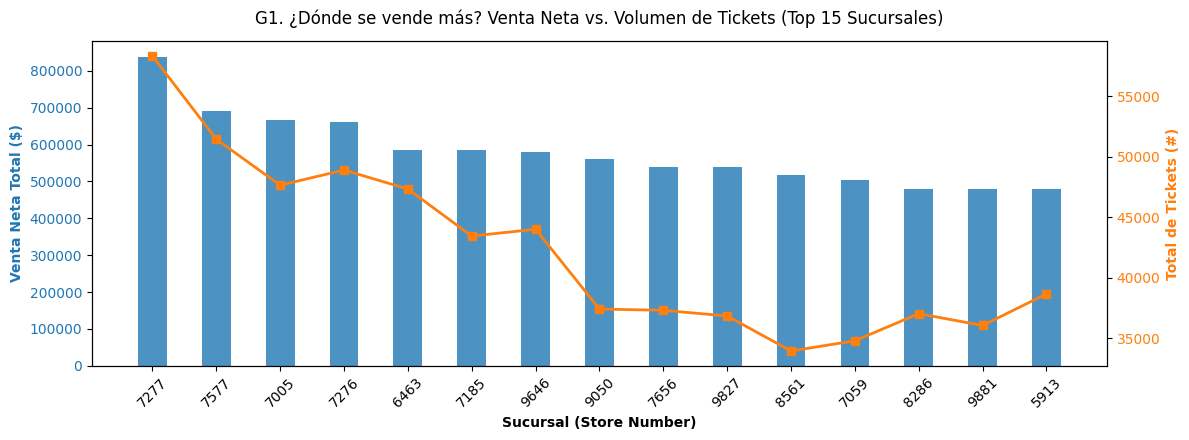

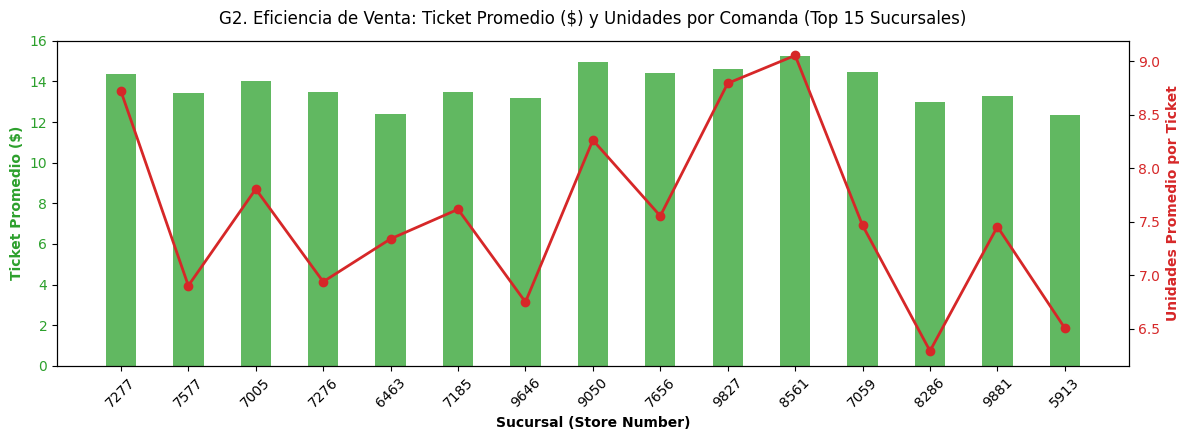

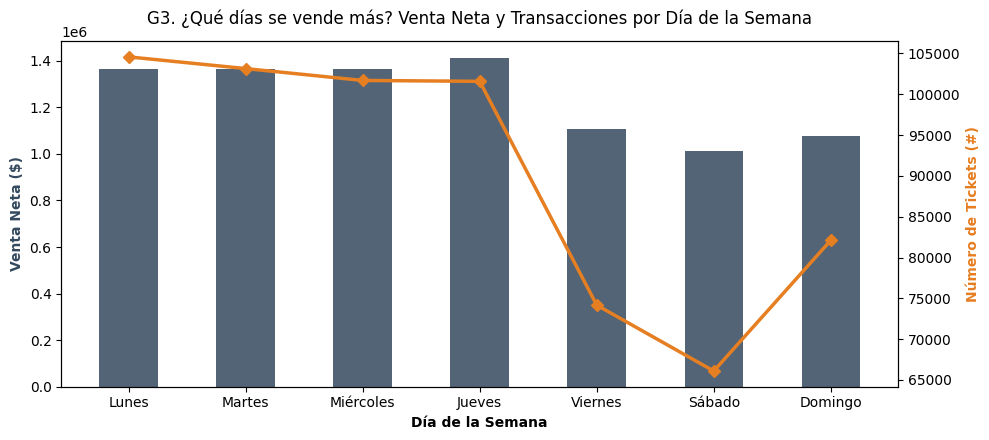

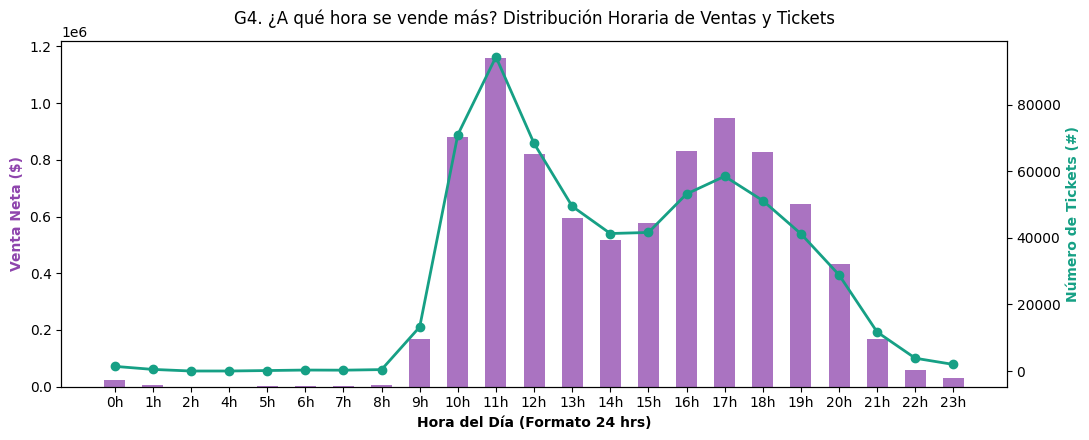

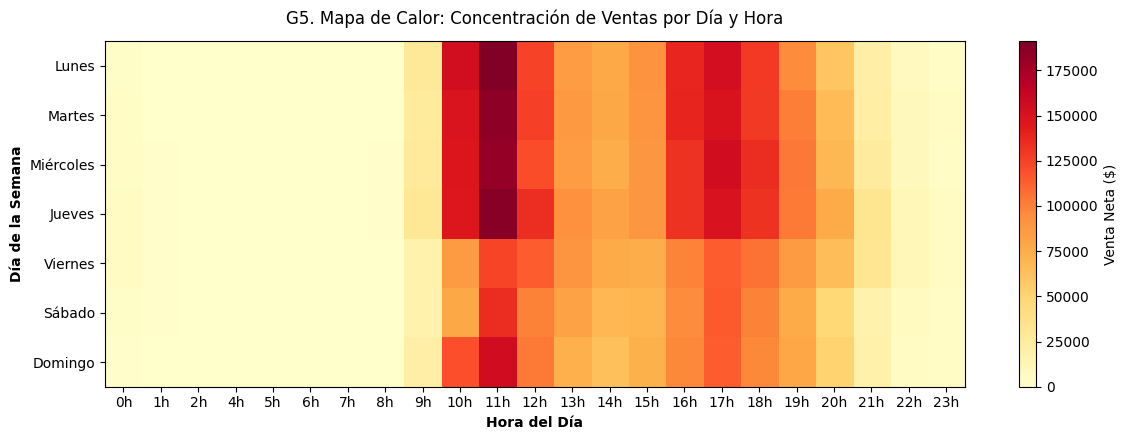

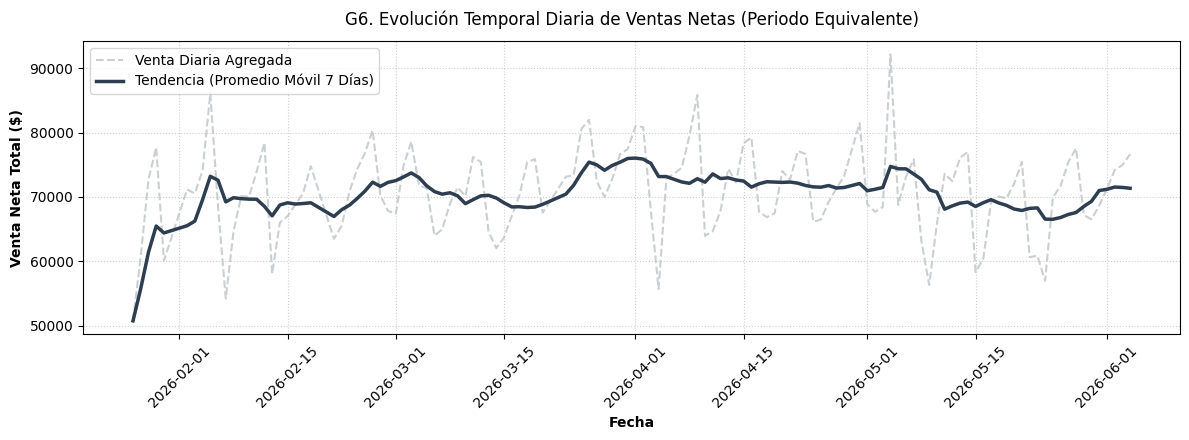

=== RESUMEN DE HALLAZGOS POR DIMENSIÓN ===

1. Sucursales Líderes (Top 15):
   - Tienda 7277: Venta = $838,773.14 | Tickets = 58,341 | Ticket Prom. = $14.38
   - Tienda 7577: Venta = $691,075.21 | Tickets = 51,458 | Ticket Prom. = $13.43
   - Tienda 7005: Venta = $667,568.29 | Tickets = 47,657 | Ticket Prom. = $14.01
   - Tienda 7276: Venta = $660,273.46 | Tickets = 48,912 | Ticket Prom. = $13.50
   - Tienda 6463: Venta = $586,556.24 | Tickets = 47,344 | Ticket Prom. = $12.39
   - Tienda 7185: Venta = $586,225.37 | Tickets = 43,457 | Ticket Prom. = $13.49
   - Tienda 9646: Venta = $580,426.12 | Tickets = 44,020 | Ticket Prom. = $13.19
   - Tienda 9050: Venta = $560,168.89 | Tickets = 37,426 | Ticket Prom. = $14.97
   - Tienda 7656: Venta = $538,930.70 | Tickets = 37,322 | Ticket Prom. = $14.44
   - Tienda 9827: Venta = $538,218.31 | Tickets = 36,852 | Ticket Prom. = $14.60
   - Tienda 8561: Venta = $517,831.55 | Tickets = 33,962 | Ticket Prom. = $15.25
   - Tienda 7059: Venta = $502,97

In [0]:
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

# -------------------------------------------------------------------------
# 0. CARGA Y FILTRADO INICIAL
# -------------------------------------------------------------------------
df = spark.table("workspace.default.taco_bueno_clean")

df_clean = (
    df.filter(
        (F.col("is_voided") == 0)
        & (F.col("item_voided") == 0)
        & (F.col("order_voided") == 0)
    )
    .withColumn("order_date", F.to_date("order_date"))
)

plt.style.use("default")

# -------------------------------------------------------------------------
# 1. DIAGNÓSTICO DE DÍAS FALTANTES Y PERIODO EQUIVALENTE
# -------------------------------------------------------------------------
print("=== 1. DIAGNÓSTICO DE DÍAS FALTANTES POR TIENDA ===")

min_date, max_date = df_clean.select(F.min("order_date"), F.max("order_date")).first()
print(f"Rango general de fechas: {min_date} al {max_date}")

# Generación limpia de secuencia de días
date_range = (
    spark.range(1)
    .select(F.explode(F.sequence(F.lit(min_date), F.lit(max_date), F.expr("interval 1 day"))).alias("order_date"))
)

stores = df_clean.select("store_number").distinct()
expected_days = stores.crossJoin(date_range)
actual_days = df_clean.select("store_number", "order_date").distinct()

missing_days = expected_days.join(actual_days, on=["store_number", "order_date"], how="left_anti")
missing_count = missing_days.groupBy("store_number").agg(F.count("order_date").alias("dias_faltantes"))

print("\n--- Sucursales con días faltantes (Top 15) ---")
missing_count.orderBy(F.desc("dias_faltantes")).show(15)

# Definición del periodo equivalente continuo
store_min_max = df_clean.groupBy("store_number").agg(
    F.min("order_date").alias("min_tienda"),
    F.max("order_date").alias("max_tienda")
)
start_eq = store_min_max.select(F.max("min_tienda")).first()[0]
end_eq = store_min_max.select(F.min("max_tienda")).first()[0]

print(f"-> Periodo equivalente recomendado para comparar tiendas: {start_eq} al {end_eq}\n")

df_eq = df_clean.filter((F.col("order_date") >= start_eq) & (F.col("order_date") <= end_eq))

# -------------------------------------------------------------------------
# 2. SELECCIÓN DE TOP 15 SUCURSALES Y AGRUPACIÓN POR TICKET
# -------------------------------------------------------------------------
top15_stores_df = (
    df_eq.groupBy("store_number")
    .agg(F.sum("net_item_price").alias("venta_total"))
    .orderBy(F.desc("venta_total"))
    .limit(15)
)

top15_store_list = [row["store_number"] for row in top15_stores_df.collect()]
df_eq_top15 = df_eq.filter(F.col("store_number").isin(top15_store_list))

# Agrupación previa a nivel Ticket para métricas correctas de comanda
df_tickets = df_eq_top15.groupBy(
    "store_number", "order_date", "check_number", "day_name", "day_of_week", "begin_hour", "time_period"
).agg(
    F.sum("net_item_price").alias("monto_ticket"),
    F.sum("quantity").alias("unidades_ticket")
)

# -------------------------------------------------------------------------
# 3. VISUALIZACIONES DESAGREGADAS
# -------------------------------------------------------------------------

# --- GRÁFICA 1: Ranking de Venta Neta y Número de Tickets por Sucursal ---
df_store_perf = (
    df_tickets.groupBy("store_number")
    .agg(
        F.sum("monto_ticket").alias("venta_neta_total"),
        F.count("check_number").alias("total_tickets"),
        F.avg("monto_ticket").alias("ticket_promedio"),
        F.sum("unidades_ticket").alias("unidades_totales")
    )
    .orderBy(F.desc("venta_neta_total"))
    .toPandas()
)

fig, ax1 = plt.subplots(figsize=(12, 4.5))
color1, color2 = "#1f77b4", "#ff7f0e"

ax1.set_xlabel("Sucursal (Store Number)", fontweight="bold")
ax1.set_ylabel("Venta Neta Total ($)", color=color1, fontweight="bold")
ax1.bar(df_store_perf["store_number"].astype(str), df_store_perf["venta_neta_total"], color=color1, alpha=0.8, width=0.45)
ax1.tick_params(axis="y", labelcolor=color1)
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
ax2.set_ylabel("Total de Tickets (#)", color=color2, fontweight="bold")
ax2.plot(df_store_perf["store_number"].astype(str), df_store_perf["total_tickets"], color=color2, marker="s", linewidth=2)
ax2.tick_params(axis="y", labelcolor=color2)

plt.title("G1. ¿Dónde se vende más? Venta Neta vs. Volumen de Tickets (Top 15 Sucursales)", fontsize=12, pad=12)
fig.tight_layout()
plt.show()


# --- GRÁFICA 2: Ticket Promedio ($) y Unidades por Ticket por Sucursal ---
df_store_perf["unidades_por_ticket"] = df_store_perf["unidades_totales"] / df_store_perf["total_tickets"]

fig, ax1 = plt.subplots(figsize=(12, 4.5))
color3, color4 = "#2ca02c", "#d62728"

ax1.set_xlabel("Sucursal (Store Number)", fontweight="bold")
ax1.set_ylabel("Ticket Promedio ($)", color=color3, fontweight="bold")
ax1.bar(df_store_perf["store_number"].astype(str), df_store_perf["ticket_promedio"], color=color3, alpha=0.75, width=0.45)
ax1.tick_params(axis="y", labelcolor=color3)
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
ax2.set_ylabel("Unidades Promedio por Ticket", color=color4, fontweight="bold")
ax2.plot(df_store_perf["store_number"].astype(str), df_store_perf["unidades_por_ticket"], color=color4, marker="o", linewidth=2)
ax2.tick_params(axis="y", labelcolor=color4)

plt.title("G2. Eficiencia de Venta: Ticket Promedio ($) y Unidades por Comanda (Top 15 Sucursales)", fontsize=12, pad=12)
fig.tight_layout()
plt.show()


# --- GRÁFICA 3: Venta Neta y Tickets por Día de la Semana ---
order_days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
order_days_es = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]

df_day = (
    df_tickets.groupBy("day_name")
    .agg(
        F.sum("monto_ticket").alias("venta_neta"),
        F.count("check_number").alias("total_tickets")
    )
    .toPandas()
)
df_day = df_day.set_index("day_name").reindex(order_days).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.bar(order_days_es, df_day["venta_neta"], color="#34495e", alpha=0.85, width=0.5)
ax1.set_ylabel("Venta Neta ($)", color="#34495e", fontweight="bold")
ax1.set_xlabel("Día de la Semana", fontweight="bold")

ax2 = ax1.twinx()
ax2.plot(order_days_es, df_day["total_tickets"], color="#e67e22", marker="D", linewidth=2.5)
ax2.set_ylabel("Número de Tickets (#)", color="#e67e22", fontweight="bold")

plt.title("G3. ¿Qué días se vende más? Venta Neta y Transacciones por Día de la Semana", fontsize=12, pad=12)
fig.tight_layout()
plt.show()


# --- GRÁFICA 4: Perfil Horario de Ventas y Comandas (0 a 23 hrs) ---
df_hour = (
    df_tickets.groupBy("begin_hour")
    .agg(
        F.sum("monto_ticket").alias("venta_neta"),
        F.count("check_number").alias("total_tickets")
    )
    .orderBy("begin_hour")
    .toPandas()
)

fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.bar(df_hour["begin_hour"].astype(str) + "h", df_hour["venta_neta"], color="#8e44ad", alpha=0.75, width=0.55)
ax1.set_ylabel("Venta Neta ($)", color="#8e44ad", fontweight="bold")
ax1.set_xlabel("Hora del Día (Formato 24 hrs)", fontweight="bold")

ax2 = ax1.twinx()
ax2.plot(df_hour["begin_hour"].astype(str) + "h", df_hour["total_tickets"], color="#16a085", marker="o", linewidth=2)
ax2.set_ylabel("Número de Tickets (#)", color="#16a085", fontweight="bold")

plt.title("G4. ¿A qué hora se vende más? Distribución Horaria de Ventas y Tickets", fontsize=12, pad=12)
fig.tight_layout()
plt.show()


# --- GRÁFICA 5: Mapa de Calor (Día de la Semana vs. Hora del Día) ---
df_horario_dia = (
    df_tickets.groupBy("day_name", "begin_hour")
    .agg(F.sum("monto_ticket").alias("venta_neta"))
    .toPandas()
)
pivot_time = df_horario_dia.pivot(index="day_name", columns="begin_hour", values="venta_neta").reindex(order_days).fillna(0)

fig, ax = plt.subplots(figsize=(12, 4.5))
cax = ax.imshow(pivot_time.values, cmap="YlOrRd", aspect="auto")

ax.set_xticks(range(len(pivot_time.columns)))
ax.set_xticklabels([f"{h}h" for h in pivot_time.columns])
ax.set_yticks(range(len(pivot_time.index)))
ax.set_yticklabels(order_days_es)

fig.colorbar(cax, label="Venta Neta ($)")
plt.title("G5. Mapa de Calor: Concentración de Ventas por Día y Hora", fontsize=12, pad=12)
plt.xlabel("Hora del Día", fontweight="bold")
plt.ylabel("Día de la Semana", fontweight="bold")
plt.tight_layout()
plt.show()


# --- GRÁFICA 6: Tendencia Temporal Agregada y Promedio Móvil ---
df_trend = (
    df_eq_top15.groupBy("order_date")
    .agg(F.sum("net_item_price").alias("venta_neta_diaria"))
    .orderBy("order_date")
    .toPandas()
)

df_trend["sma_7d"] = df_trend["venta_neta_diaria"].rolling(window=7, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(df_trend["order_date"], df_trend["venta_neta_diaria"], color="#bdc3c7", alpha=0.8, linestyle="--", label="Venta Diaria Agregada")
ax.plot(df_trend["order_date"], df_trend["sma_7d"], color="#2c3e50", linewidth=2.5, label="Tendencia (Promedio Móvil 7 Días)")

plt.title("G6. Evolución Temporal Diaria de Ventas Netas (Periodo Equivalente)", fontsize=12, pad=12)
plt.xlabel("Fecha", fontweight="bold")
plt.ylabel("Venta Neta Total ($)", fontweight="bold")
plt.legend(loc="upper left")
plt.xticks(rotation=45)
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# 4. IMPRESIÓN DE HALLAZGOS Y MÉTRICAS RESUMEN
# -------------------------------------------------------------------------
print("=== RESUMEN DE HALLAZGOS POR DIMENSIÓN ===")
print("\n1. Sucursales Líderes (Top 15):")
for _, row in df_store_perf.iterrows():
    print(f"   - Tienda {row['store_number']}: Venta = ${row['venta_neta_total']:,.2f} | Tickets = {row['total_tickets']:,} | Ticket Prom. = ${row['ticket_promedio']:.2f}")

top_hour = df_tickets.groupBy("begin_hour").agg(F.sum("monto_ticket").alias("v")).orderBy(F.desc("v")).first()
top_day = df_tickets.groupBy("day_name").agg(F.sum("monto_ticket").alias("v")).orderBy(F.desc("v")).first()

print(f"\n2. Patrón Temporal:")
print(f"   - Hora Pico de Mayor Venta: {top_hour['begin_hour']}:00 hrs.")
print(f"   - Día Más Fuerte de la Semana: {top_day['day_name']}")